# 第6章 numba で速くする ―― 研究と同じ条件で IV マップを作る

**この章でできるようになること**
- `@njit` を付けて、Python の `for` を機械語なみの速さにできる
- 「初回はコンパイルで遅い」「`cache=True` で次回から速い」を理解する
- `prange` で CPU の複数のコアに仕事を分けられる
- 研究と同じ条件（dt = 1/32、N_run = N_avg = 20106）で β = 10 の IV マップを作り、保存できる

**例え：** ふつうの Python は「**通訳を介した会話**」です。1文ごとに通訳（インタプリタ）が訳すので遅くなります。numba は、話す内容を**前もって全部翻訳した原稿**（機械語）を作っておくようなものです。翻訳には最初に少し時間がかかりますが、あとは速く読めます。`prange` は、その原稿を**4人で手分けして読む**ことです。

| 用語 | 意味 | 例え |
|---|---|---|
| インタプリタ | プログラムを1行ずつ読んで実行するしくみ（ふつうの Python） | 同時通訳 |
| コンパイル | プログラムを前もって機械語に直すこと | 原稿をまるごと翻訳しておく |
| JIT（実行時コンパイル） | 関数が最初に呼ばれたときにコンパイルすること | 本番の直前に翻訳する |
| numba | Python の関数を JIT コンパイルするライブラリ | 翻訳係 |
| `@njit` | 「この関数を numba でコンパイルして」という印（デコレータ） | 原稿に貼る「翻訳してください」の付箋 |
| デコレータ | 関数の上に `@名前` と書いて、関数に機能を足すしくみ | 付箋 |
| 並列計算 | 仕事を分けて、複数のコアで同時に計算すること | 4人で手分けする |
| `prange` | numba で「この for は並列にしてよい」という印 | 「ここは手分けしてよい」の指示 |
| IV マップ | 電流 × 振幅のすべての組で求めた電圧の表 `V[電流, 振幅]` | 縦横に区切った成績表 |

> 研究コードとのつながり：`py/rcsj.py` は `@njit(cache=True)` と `@njit(parallel=True)`・`prange` を使っています。この教材の `kyozai/rcsj_mini.py` はその書き直しで、手順は同じです。

In [1]:
# 準備：教材の部品（kyozai/）を import できるようにする。どの章でも最初に1回だけ実行する。
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "kyozai").exists():   # kyozai/ があるフォルダまで上にたどる
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("教材の場所:", ROOT.name)

教材の場所: python-from-my-research


## 6.1 遅い関数を用意する

第5章の1点の計算を、numba で使える形（NumPy 配列を作らず、数だけで計算する形）に書き直します。まずは numba なしで時間を測ります。

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time, os
from numba import njit, prange

def accel_py(t, g, G, I, b, A, O1, O2):
    return I - b*G - np.sin(g) + A*np.sin(O1*t) + A*np.sin(O2*t)

def steady_py(I, b, A, O1, O2, dt, N_run, N_avg, initial):
    g, G, t, s = 0.0, initial, 0.0, 0.0
    for k in range(N_run + N_avg):
        k1 = accel_py(t, g, G, I, b, A, O1, O2)*dt;                   j1 = G*dt
        k2 = accel_py(t+dt/2, g+j1/2, G+k1/2, I, b, A, O1, O2)*dt;    j2 = (G+k1/2)*dt
        k3 = accel_py(t+dt/2, g+j2/2, G+k2/2, I, b, A, O1, O2)*dt;    j3 = (G+k2/2)*dt
        k4 = accel_py(t+dt, g+j3, G+k3, I, b, A, O1, O2)*dt;          j4 = (G+k3)*dt
        g += (j1 + 2*j2 + 2*j3 + j4)/6; G += (k1 + 2*k2 + 2*k3 + k4)/6; t += dt
        if k >= N_run:
            s += G
    v = s / N_avg
    return v if v > 0 else 0.0

N = 20106          # 研究と同じ N_run = N_avg
t0 = time.time()
v_py = steady_py(3.0, 10.0, 20.0, 0.5, 0.8, 1/32, N, N, 1.0)
t_py = time.time() - t0
print(f"Python のまま: V = {v_py:.5f}, {t_py:.2f} 秒（1点）")

Python のまま: V = 0.29984, 0.22 秒（1点）


1点でも目に見える時間がかかります（計算機によります）。研究の β=10 の保存データは1本の IV 曲線に約 800 点、それが何十本もあるので、このままでは何時間もかかります。

## 6.2 @njit を付ける

関数の上に `@njit` と書くだけです。中身は1文字も変えません。

In [3]:
@njit
def accel_nb(t, g, G, I, b, A, O1, O2):
    return I - b*G - np.sin(g) + A*np.sin(O1*t) + A*np.sin(O2*t)

@njit
def steady_nb(I, b, A, O1, O2, dt, N_run, N_avg, initial):
    g, G, t, s = 0.0, initial, 0.0, 0.0
    for k in range(N_run + N_avg):
        k1 = accel_nb(t, g, G, I, b, A, O1, O2)*dt;                   j1 = G*dt
        k2 = accel_nb(t+dt/2, g+j1/2, G+k1/2, I, b, A, O1, O2)*dt;    j2 = (G+k1/2)*dt
        k3 = accel_nb(t+dt/2, g+j2/2, G+k2/2, I, b, A, O1, O2)*dt;    j3 = (G+k2/2)*dt
        k4 = accel_nb(t+dt, g+j3, G+k3, I, b, A, O1, O2)*dt;          j4 = (G+k3)*dt
        g += (j1 + 2*j2 + 2*j3 + j4)/6; G += (k1 + 2*k2 + 2*k3 + k4)/6; t += dt
        if k >= N_run:
            s += G
    v = s / N_avg
    return v if v > 0 else 0.0

t0 = time.time(); v1 = steady_nb(3.0, 10.0, 20.0, 0.5, 0.8, 1/32, N, N, 1.0); t1 = time.time() - t0
t0 = time.time(); v2 = steady_nb(3.0, 10.0, 20.0, 0.5, 0.8, 1/32, N, N, 1.0); t2 = time.time() - t0
print(f"1回目（コンパイル込み）: {t1:.3f} 秒")
print(f"2回目                  : {t2*1000:.2f} ミリ秒   → Python の約 {t_py/t2:.0f} 倍速い")
print(f"Python 版との差: {abs(v_py - v2):.1e}")

1回目（コンパイル込み）: 0.615 秒
2回目                  : 4.72 ミリ秒   → Python の約 46 倍速い
Python 版との差: 0.0e+00


1回目はコンパイルの時間が入るので遅く、2回目からとても速くなります。答えの差は、小数の丸め誤差くらい（0 か、とても小さい数）です。

**numba で気をつけること**
- 使えるのは、数・NumPy 配列・`for`・`if` などの基本だけです。辞書や自作のクラス、matplotlib などは中で使えません。
- `@njit(cache=True)` にすると、コンパイル結果をファイルに保存して、次に Python を起動したときもすぐ速くなります（研究コードはこれを使っています）。

## 6.3 prange で手分けする

IV マップは「電流 × 振幅」の全部の組で `steady` を呼びます。組どうしは互いに関係ないので、手分けできます。`parallel=True` と `prange` を使います。

In [4]:
@njit(parallel=True)
def iv_map_nb(Iarr, Alist, b, O1, O2, dt=1/32, N_run=20106, N_avg=20106, initial=1.0):
    M, nA = Iarr.size, Alist.size
    out = np.zeros((M, nA))
    for p in prange(M * nA):        # 1本の通し番号 p を、(電流 i, 振幅 a) に戻す
        i = p // nA
        a = p % nA
        out[i, a] = steady_nb(Iarr[i], b, Alist[a], O1, O2, dt, N_run, N_avg, initial)
    return out

I_test = np.linspace(1.6, 4.2, 40); A_test = np.array([0.0, 20.0])
iv_map_nb(I_test[:2], A_test[:1], 10.0, 0.5, 0.8)       # コンパイルだけ先にすませる

t0 = time.time(); out = iv_map_nb(I_test, A_test, 10.0, 0.5, 0.8); t_par = time.time() - t0
t0 = time.time()
out_serial = np.array([[steady_nb(I, 10.0, A, 0.5, 0.8, 1/32, N, N, 1.0) for A in A_test] for I in I_test])
t_ser = time.time() - t0
print(f"コアの数: {os.cpu_count()}")
print(f"1コアで順番に: {t_ser:.2f} 秒 / prange: {t_par:.2f} 秒")
print("同じ答えか:", np.array_equal(out, out_serial))

コアの数: 4
1コアで順番に: 0.39 秒 / prange: 0.10 秒
同じ答えか: True


`p // nA` は割り算の商、`p % nA` は余りです。2重の `for` を1本にまとめているのは、研究コードと同じ書き方で、コアに仕事を均等に分けやすくするためです。

## 6.4 研究と同じ条件で IV マップを作る

ここからは教材の部品 `kyozai/rcsj_mini.py` の `iv_map` を使います。中身は 6.3 と同じで、研究の `py/rcsj.py` と同じ手順です。

条件（`kyozai/data.py` の `iv_beta10`）：
- β = 10、Ω₁ = 0.5、Ω₂ = 0.8、dt = 1/32、N_run = N_avg = 20106、initial = 1.0
- 電流：研究の保存データと同じ刻み 0.0070779 で、V = 0.3 付近の **I = 1.6〜4.2 だけ**（時間の節約のため。研究の保存データはもっと広い範囲）
- 振幅：A = 0〜64 を 33 点

1回目は計算して `data/iv_beta10_O2_0.80.npz` に保存します（4コアで20秒前後）。2回目からはファイルを読むだけです。

In [5]:
from kyozai.data import iv_beta10

t0 = time.time()
d = iv_beta10(O2=0.8)
print(f"{time.time() - t0:.1f} 秒")
I, A, V = d["I"], d["A"], d["V"]
print("I:", I.size, "点", " A:", A.size, "点", " V の形:", V.shape)

17.9 秒
I: 368 点  A: 33 点  V の形: (368, 33)


## 6.5 IV 曲線を何本か描く

`V[:, a]` が振幅 `A[a]` のときの IV 曲線です（第2章）。

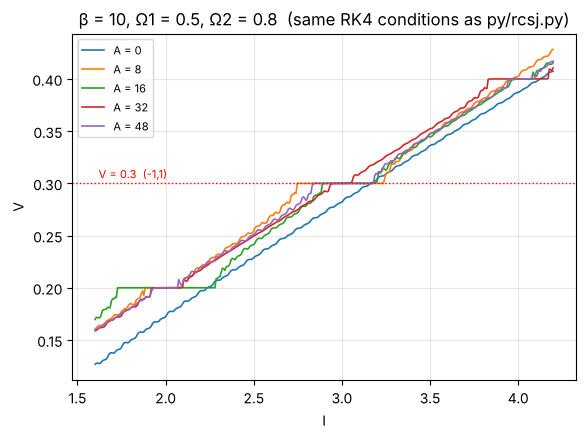

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for a in [0, 4, 8, 16, 24]:
    ax.plot(I, V[:, a], lw=1.2, label=f"A = {A[a]:.0f}")
ax.axhline(0.3, color="r", ls=":", lw=1)
ax.text(1.62, 0.305, "V = 0.3  (-1,1)", color="r", fontsize=8)
ax.set_xlabel("I"); ax.set_ylabel("V"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title("β = 10, Ω1 = 0.5, Ω2 = 0.8  (same RK4 conditions as py/rcsj.py)")
plt.show()

## 6.6 マップ全体を色で見る

段（ステップ）の上では V が I によらず一定なので、**傾き dV/dI がほぼ 0** になります。傾きを色で描くと、段が見つけやすくなります。

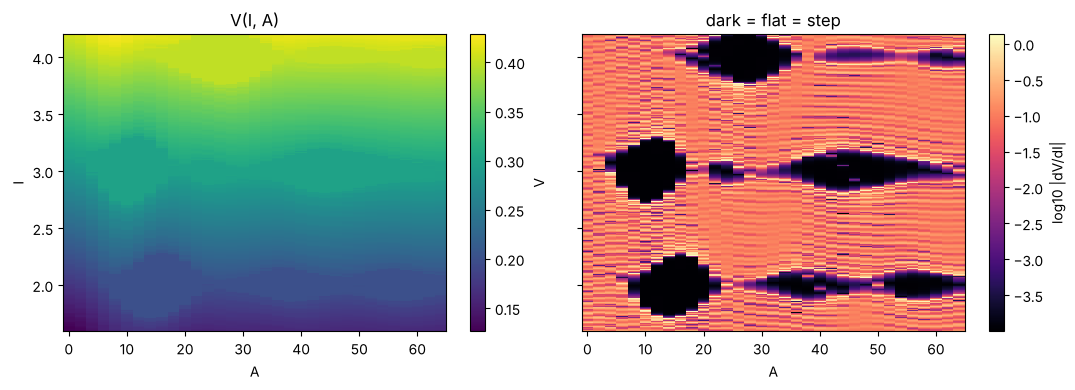

In [7]:
dVdI = np.diff(V, axis=0) / np.diff(I)[:, None]     # 電流の方向（axis=0）に差をとる
Im = (I[1:] + I[:-1]) / 2

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
pc0 = ax[0].pcolormesh(A, I, V, shading="auto", cmap="viridis")
fig.colorbar(pc0, ax=ax[0], label="V")
ax[0].set_title("V(I, A)")
pc1 = ax[1].pcolormesh(A, Im, np.log10(np.abs(dVdI) + 1e-4), shading="auto", cmap="magma")
fig.colorbar(pc1, ax=ax[1], label="log10 |dV/dI|")
ax[1].set_title("dark = flat = step")
for a_ in ax:
    a_.set_xlabel("A")
ax[0].set_ylabel("I")
fig.tight_layout(); plt.show()

右の図の暗い帯が段です。A を大きくすると、帯が太くなったり細くなったり（消えたり）します。この「段の幅が A でどう変わるか」を数にするのが次の章です。

## 練習問題

1. 6.2 の `steady_nb` を使って、A = 20 のとき I = 2.5〜3.5 を 50 点、for で V を求めて IV 曲線を描いてください。1点あたりの時間はどれくらいですか。
2. `iv_map_nb` の `prange` を普通の `range` に変えると、時間はどう変わりますか。（`parallel=True` のままでも動きます）

<details><summary>答え</summary>

```python
# 1.
Is = np.linspace(2.5, 3.5, 50)
t0 = time.time()
Vs = [steady_nb(x, 10.0, 20.0, 0.5, 0.8, 1/32, N, N, 1.0) for x in Is]
print((time.time() - t0) / 50, "秒/点")
plt.plot(Is, Vs); plt.show()
```
2. `range` にすると並列にならないので遅くなります。どれくらい遅くなるかはコアの数と計算の量によります（コアの数より大きく速くなることはありません）。6.3 の出力の「1コアで順番に」と「prange」の比が目安です。
</details>

## まとめ
- `@njit` を付けるだけで、`for` だらけの RK4 が何十倍も速くなる（倍率は計算機による。1回目はコンパイルで遅い）。
- `prange` で、互いに関係のない計算をコアに手分けできる。
- 研究と同じ条件で β = 10 の IV マップを作り、`data/` に保存した。次の章からこれを使う。